# Evaluation of Deep Learning Models (Multi-class)

This notebook evaluates trained multi-class segmentation models across all predicted classes.
Unlike the binary evaluation, we evaluate the performance of each class (clouds, sand, water, wet sand, white water) globally in the patch without collapsing them.

## Evaluation Strategy

- For each patch in the test dataset
- Predict the multi-class mask using the DL model 
- For each valid class, calculate IoU and Dice metrics against the Ground Truth (excluding ignore pixels `255`)
- Aggregate results into a DataFrame for class-wise analysis

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

# Add project root to sys.path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

# Import utility functions if needed (none strictly needed for multi-class since it's local logic)
from notebooks.utils.evaluation_utils import calculate_metrics

# Import Deep Learning utilities
from src.dl_models import get_model, CoastlineDataset

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("Libraries imported successfully!")

/opt/anaconda3/envs/s2_benchmark/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully!


## Configuration

Define paths, models, class mappings, boundary zone parameters and load datasets.

**Note:** PyTorch `CoastlineDataset` subtracts 1 from all classes mapping values from 1-5 to 0-4 (with 255 as ignore_index):
* Original 3 & 5 $\rightarrow$ Mapped 2 & 4 (Water classes)
* Original 2 & 4 $\rightarrow$ Mapped 1 & 3 (No-water / land classes)
* Original 1 & 255 $\rightarrow$ Mapped 0 & 255 (Ignored classes)

In [2]:
# Target Study Areas and General setup
STUDY_NAMES = ["puntal", "salinas"]

# Base directories
BASE_DIR = Path("..") / "data"
TEST_NPY_DIR = BASE_DIR / "dl_npy" / "test"
MODELS_DIR = Path("..") / "results" / "models"

# Available Models to Evaluate
EVAL_MODELS = [
    {
        "name": "unet_resnet34",
        "arch": "unet",
        "encoder": "resnet34",
        "filepath": MODELS_DIR / "best_model_unet_resnet34.pth"
    }
]

# Inference parameters
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
BATCH_SIZE = 1 # Keep 1 for patch-level inference tracking

# Multi-class Evaluation
# As mapped by PyTorch CoastlineDataset (0-indexed, excluding 255 which is ignore_index)
TARGET_CLASSES = {
    0: 'clouds',
    1: 'sand',
    2: 'water',
    3: 'wet_sand',
    4: 'white_water'
}
IGNORE_INDEX = 255

print(f"Device: {DEVICE}")
print(f"Target Classes: {TARGET_CLASSES}")

Device: mps
Target Classes: {0: 'clouds', 1: 'sand', 2: 'water', 3: 'wet_sand', 4: 'white_water'}


## Initialize Dataset and DataLoader
Prepare the Test Dataset DataLoader that will fetch patches from the test split.

In [3]:
# Initialize Dataset and DataLoader
test_dataset = CoastlineDataset(split_dir=TEST_NPY_DIR, transform=None)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Loaded {len(test_dataset)} test patches.")
# Make sure we have metadata that maps correctly to evaluation output
print(f"Dataset has metadata columns: {list(test_dataset.metadata.columns)}")

Loaded 25 test patches.
Dataset has metadata columns: ['sample_id', 'study_name', 'timestamp', 'tide', 'tide_is_rising', 'tide_level_quantile', 'image_npy_path', 'mask_npy_path', 'source_gt_path', 'source_rgb_path', 'source_ms_path', 'source_swir_path']


## Inference and Evaluate Class Metrics
Iterate through the test patches, output predictions, compare with ground truth bounding zone and aggregate the metrics *per class* using pandas.

In [4]:
def run_evaluation_loop(test_loader, eval_models):
    results = []

    for model_config in eval_models:
        model_filepath = model_config["filepath"]
        if not model_filepath.exists():
            print(f"Skipping {model_config['name']}: {model_filepath} not found.")
            continue
            
        print(f"\n============================================================")
        print(f"Evaluating Model: {model_config['name']}")
        print(f"============================================================")
        
        # Instantiate Model
        model = get_model(arch=model_config["arch"], encoder_name=model_config["encoder"])
        
        # Load weights explicitly
        state_dict = torch.load(model_filepath, map_location=DEVICE, weights_only=True)
        model.load_state_dict(state_dict)
        model.to(DEVICE)
        model.eval()

        with torch.no_grad():
            for dt_idx, (image_tensor, gt_mask_tensor) in enumerate(tqdm(test_loader, desc=f"Evaluating Patches")):
                image_tensor = image_tensor.float().to(DEVICE)
                
                # Model inference prediction
                logits = model(image_tensor)
                pred_mask = torch.argmax(logits, dim=1).cpu().numpy().squeeze(0)  # Shape (128,128)
                gt_mask = gt_mask_tensor.numpy().squeeze(0)                       # Shape (128,128)
                
                row = test_dataset.metadata.iloc[dt_idx]
                dt_obj = pd.to_datetime(row['timestamp'])
                
                base_result = {
                    'study_name': row['study_name'],
                    'date': dt_obj.strftime("%Y-%m-%d"),
                    'time': dt_obj.strftime("%H-%M-%S").replace(':', '-'),
                    'tile': '30TVP', # Default inference string if not mapped
                    'site': row['study_name'].upper(),
                    'patch_id': dt_idx,
                    'model': model_config['name'],
                    'arch': model_config['arch'],
                    'encoder': model_config['encoder']
                }

                valid_mask = (gt_mask != IGNORE_INDEX)
                
                # Evaluate Per-Class
                for class_idx, class_name in TARGET_CLASSES.items():
                    # Generate binary boolean masks for current target class
                    gt_c = (gt_mask == class_idx)
                    pred_c = (pred_mask == class_idx)
                    
                    intersection = (gt_c & pred_c & valid_mask).sum()
                    union = ((gt_c | pred_c) & valid_mask).sum()
                    
                    gt_sum = (gt_c & valid_mask).sum()
                    pred_sum = (pred_c & valid_mask).sum()
                    
                    if union == 0 and gt_sum == 0 and pred_sum == 0:
                         # Class not present in GT or Prediction, so nothing to evaluate
                         continue
                    
                    iou = intersection / union if union > 0 else 0.0
                    dice = 2 * intersection / (gt_sum + pred_sum) if (gt_sum + pred_sum) > 0 else 0.0

                    class_result = base_result.copy()
                    class_result.update({
                        'class_name': class_name,
                        'class_id': class_idx,
                        'iou': iou,
                        'dice': dice,
                        'gt_pixels': gt_sum,
                        'pred_pixels': pred_sum
                    })
                    
                    results.append(class_result)

    return pd.DataFrame(results)

df_results = run_evaluation_loop(test_loader, EVAL_MODELS)
print(f"Evaluated {len(df_results)} class predictions across patches.")
display(df_results.head(10))


Evaluating Model: unet_resnet34


Evaluating Patches: 100%|██████████| 25/25 [00:00<00:00, 62.24it/s]

Evaluated 95 class predictions across patches.


,study_name,date,time,tile,site,patch_id,model,arch,encoder,class_name,class_id,iou,dice,gt_pixels,pred_pixels
0,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,0,unet_resnet34,unet,resnet34,sand,1,0.896277,0.945302,352,361
1,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,0,unet_resnet34,unet,resnet34,water,2,0.981225,0.990524,5414,5455
2,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,0,unet_resnet34,unet,resnet34,wet_sand,3,0.410256,0.581818,75,90
3,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,0,unet_resnet34,unet,resnet34,white_water,4,0.162500,0.279570,79,14
4,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,1,unet_resnet34,unet,resnet34,sand,1,0.933333,0.965517,513,531
5,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,1,unet_resnet34,unet,resnet34,water,2,0.963115,0.981211,9886,10232
6,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,1,unet_resnet34,unet,resnet34,wet_sand,3,0.429530,0.600939,132,81
7,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,1,unet_resnet34,unet,resnet34,white_water,4,0.216019,0.355289,407,94
8,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,2,unet_resnet34,unet,resnet34,sand,1,0.940789,0.969492,719,756
9,puntal,2017-10-14,11-00-00,30TVP,PUNTAL,2,unet_resnet34,unet,resnet34,water,2,0.908332,0.951965,7647,8362


## Summary Statistics and Visualizations
Print descriptive statistics for the U-Net boundaries. Compare metrics directly.

Deep learning evaluation results saved to: ../data/../results/dl_multiclass_metrics_results.csv
--- Deep Learning Segmentation (Multi-class Overall) ---
Count (Valid evaluation occurrences): 95
Mean IoU (Overall): 0.6774
Mean Dice (Overall): 0.7510
-------------------\n

Model: unet_resnet34

Mean Metrics Grouped by Class:


,iou,dice
class_name,,
water,0.881355,0.909971
sand,0.682225,0.751128
clouds,0.668247,0.737986
wet_sand,0.613642,0.703746
white_water,0.494180,0.611386



Mean Metrics Grouped by Study Area:


iou      dice
study_name class_name                     
puntal     sand         0.908174  0.951479
           water        0.974026  0.986646
           wet_sand     0.700987  0.800963
           white_water  0.220929  0.360253
salinas    clouds       0.668247  0.737986
           sand         0.561719  0.644274
           water        0.835020  0.871633
           wet_sand     0.567057  0.651898
           white_water  0.567048  0.678355

Figure saved to: ../data/../results/dl_multiclass_evaluation_overview.png


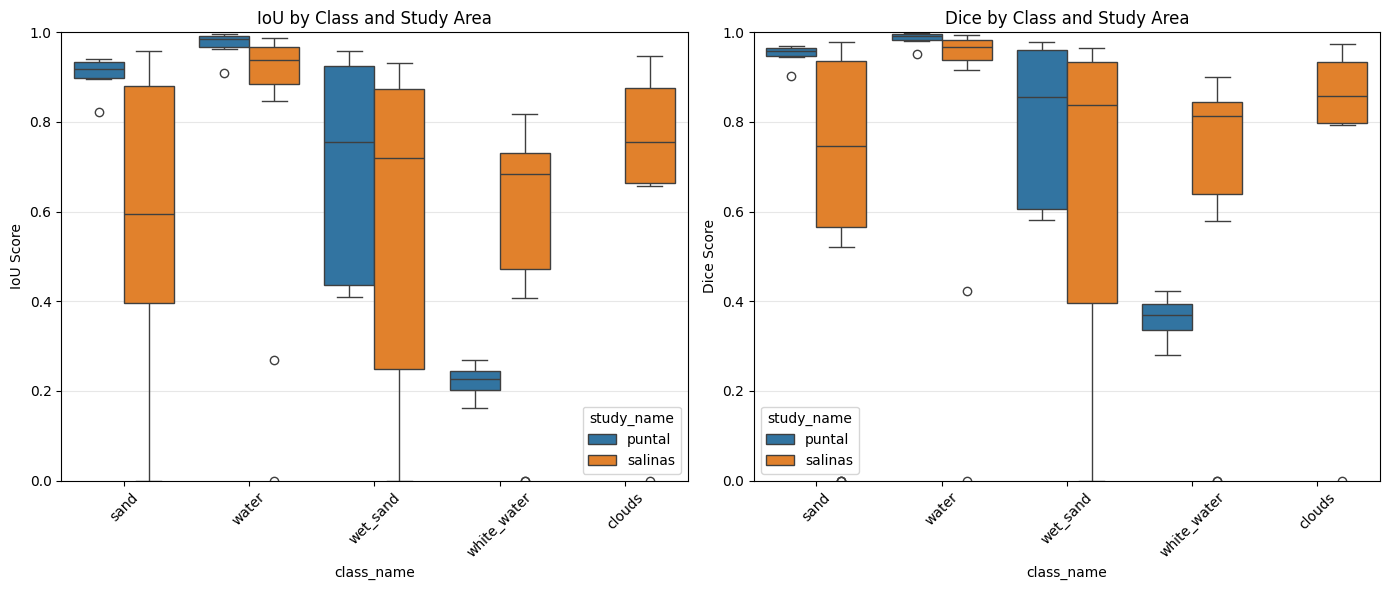

In [5]:
# Ensure results output directory
output_dir = BASE_DIR / ".." / "results"
output_dir.mkdir(parents=True, exist_ok=True)

# Save inference
output_file = output_dir / "dl_multiclass_metrics_results.csv"
df_results.to_csv(output_file, index=False)
print(f"Deep learning evaluation results saved to: {output_file}")

# Print summary stats
def print_summary_stats(df, title):
    print(f"--- {title} ---")
    print(f"Count (Valid evaluation occurrences): {len(df)}")
    print(f"Mean IoU (Overall): {df['iou'].mean():.4f}")
    print(f"Mean Dice (Overall): {df['dice'].mean():.4f}")
    print("-------------------\\n")

print_summary_stats(df_results, "Deep Learning Segmentation (Multi-class Overall)")

for model_name in df_results['model'].unique():
    model_df = df_results[df_results['model'] == model_name]
    print(f"\n=====================================")
    print(f"Model: {model_name}")
    print(f"=====================================")
    print("\nMean Metrics Grouped by Class:")
    display(model_df.groupby('class_name')[['iou', 'dice']].mean().sort_values(by='iou', ascending=False))
    
    print("\nMean Metrics Grouped by Study Area:")
    display(model_df.groupby(['study_name', 'class_name'])[['iou', 'dice']].mean())

# Plotting metrics
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.boxplot(
    data=df_results, 
    x='class_name', 
    y='iou', 
    hue='study_name', 
)
plt.title('IoU by Class and Study Area')
plt.ylabel('IoU Score')
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.grid(True, axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
sns.boxplot(
    data=df_results, 
    x='class_name', 
    y='dice', 
    hue='study_name', 
)
plt.title('Dice by Class and Study Area')
plt.ylabel('Dice Score')
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.grid(True, axis='y', alpha=0.3)

plt.tight_layout()

# Save figure
plot_output_file = output_dir / "dl_multiclass_evaluation_overview.png"
plt.savefig(plot_output_file, dpi=300, bbox_inches='tight')
print(f"Figure saved to: {plot_output_file}")
plt.show()